# v17b — the comparison

Every method here produces a score in [0,1]. **The same nested per-context threshold protocol
is applied to all of them** — threshold at the 90th percentile of a calibration half of that
context's benign scores, measured on the held-out half, 400 resamples — so ASR at a 10% FPR
budget is directly comparable.

## The asymmetry, stated up front

MSLSAM is **trained on this corpus**. Every baseline is **zero-shot**. Comparing them directly
flatters MSLSAM and would be dishonest, so two comparisons are reported:

| comparison | MSLSAM arm | fair? |
|---|---|---|
| **in-distribution** | grouped CV, family seen in training | **No** — upper bound only |
| **leave-one-corpus-out** | that family removed from training entirely | **Yes** — neither has seen it |

The LOCO row is the one that belongs in the thesis next to the baselines. The in-distribution
row is the ceiling MSLSAM reaches when it *has* seen the family.

## Four questions

1. **Does MSLSAM beat the floor?** If regex matches it on SPML, the headline collapses.
2. **Does it beat a dedicated classifier, zero-shot vs zero-shot?**
3. **Does it beat the same model judging itself in one forward pass?** Same compute, different
   reading of the prompt.
4. **Do the baselines share the instruction/injection confusion?** If ProtectAI and the judge
   also fire on tier-2 hard negatives at 50–80%, that confusion is a property of **the task**,
   not of MSLSAM — which makes it a far more interesting finding than a flaw in one method.

In [8]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score
warnings.filterwarnings("ignore"); sns.set_style("whitegrid")

SEED, N_THRESH, FPR_BUDGET = 42, 400, 0.10
PCA_DIMS, N_SPLITS = 512, 5
RES, FIG = "results/v17", "mslsamv17"
os.makedirs(RES, exist_ok=True); os.makedirs("outputs", exist_ok=True)

# Scores live one-file-per-method in results/v17/scores/, written by v17a (rules, small
# classifiers) and v17a2 (the 8B judge). Anything missing is simply absent from the table.
SC_DIR = "results/v17/scores"
corpus = pd.read_csv("datasets/unified/injection_corpus_v15.csv").reset_index(drop=True)
keep = (corpus.corpus != "Baseline-Dolly").values
S = pd.DataFrame({"row": np.arange(int(keep.sum())),
                  "label": corpus.label.values[keep], "corpus": corpus.corpus.values[keep]})
r = pd.read_csv(f"{SC_DIR}/_rows.csv")
assert len(r) == len(S) and (r.corpus.values == S.corpus.values).all() \
       and (r.label.values == S.label.values).all(), "scores were written against a different row order"
for f in sorted(os.listdir(SC_DIR)):
    if f.endswith(".npy") and not f.startswith("_"):
        a = np.load(f"{SC_DIR}/{f}")
        assert len(a) == len(S), f"{f}: {len(a)} scores for {len(S)} rows"
        S[f[:-4]] = a
COST = {f[:-len(".cost.json")]: json.load(open(f"{SC_DIR}/{f}"))
        for f in os.listdir(SC_DIR) if f.endswith(".cost.json")}
COST_KEY = {"rule_count": "rule_keyword", "rule_binary": "rule_keyword",      # one cost, two columns
            "tfidf_lr_indist": "tfidf_lr", "tfidf_lr_loco": "tfidf_lr",
            "minilm_lr_indist": "minilm_probe", "minilm_lr_loco": "minilm_probe",
            "minilm_hgb_indist": "minilm_probe", "minilm_hgb_loco": "minilm_probe"}
CACHE = "representation_cache/joined_v16"
man  = json.load(open(f"{CACHE}/manifest.json")); LAYERS = man["layers"]
rows = pd.read_csv(f"{CACHE}/rows_v16.csv").reset_index(drop=True)



METHODS = [c for c in S.columns if c not in ("row", "label", "corpus")]
print(f"{len(S):,} rows | baseline methods: {METHODS}")
for m in METHODS:
    n = S[m].notna().sum()
    note = "" if n == len(S) else ("  (LOCO: 4 held-out families only; WJB/XSTest/JBB not held out)"
                                   if m.endswith("_loco") else f"  ({n/len(S)*100:.0f}% subsample)")
    print(f"  {m:<22}{n:>7,} scored" + note)

11,245 rows | baseline methods: ['llm_judge', 'minilm_hgb_indist', 'minilm_hgb_loco', 'minilm_lr_indist', 'minilm_lr_loco', 'promptguard2_86m', 'protectai_deberta', 'rule_binary', 'rule_count', 'tfidf_lr_indist', 'tfidf_lr_loco']
  llm_judge               3,487 scored  (31% subsample)
  minilm_hgb_indist      11,245 scored
  minilm_hgb_loco         7,595 scored  (LOCO: 4 held-out families only; WJB/XSTest/JBB not held out)
  minilm_lr_indist       11,245 scored
  minilm_lr_loco          7,595 scored  (LOCO: 4 held-out families only; WJB/XSTest/JBB not held out)
  promptguard2_86m       11,245 scored
  protectai_deberta      11,245 scored
  rule_binary            11,245 scored
  rule_count             11,245 scored
  tfidf_lr_indist        11,245 scored
  tfidf_lr_loco           7,595 scored  (LOCO: 4 held-out families only; WJB/XSTest/JBB not held out)


In [9]:
# ---- MSLSAM scores: in-distribution AND leave-one-corpus-out ---------------
is_base = (rows.corpus == "Baseline-Dolly").values
ev = rows[~is_base].reset_index(drop=True)
ev_rows = np.where(~is_base)[0]
assert len(ev) == len(S) and (ev.corpus.values == S.corpus.values).all(), "cache/score misalign"

PC, MU, CINV = {}, {}, {}
for li in LAYERS:
    X = np.load(f"{CACHE}/layer_{li}.npy")
    N_PCA = min(PCA_DIMS, int(is_base.sum()) - 1, X.shape[1])
    p = PCA(n_components=N_PCA, random_state=SEED).fit(X[is_base])   # seeded: auto -> randomized SVD here; unseeded it drifted MSLSAM 0.2-0.6 pts between runs
    Z = p.transform(X).astype(np.float32); PC[li] = Z[ev_rows]
    b = p.transform(X[is_base]); MU[li] = b.mean(0)
    CINV[li] = np.linalg.inv(np.cov(b.T) + np.eye(N_PCA) * 1e-4)
    del X, Z, b
print(f"PCA {N_PCA}/layer")

def _norm(A): return A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-8)
def max_cos_exact(q, pr, li):
    Sm = _norm(PC[li][q]) @ _norm(PC[li][pr]).T
    pos = {int(r): j for j, r in enumerate(pr)}
    for i_, r in enumerate(q):
        j = pos.get(int(r))
        if j is not None: Sm[i_, j] = -np.inf
    return Sm.max(axis=1)
def mahal(Z, li):
    d = Z - MU[li]; return np.sqrt(np.einsum("ij,jk,ik->i", d, CINV[li], d))
FAM = ["direct", "indirect"]
def features(rws, proto):
    cols = []
    for f in FAM:
        pr = proto.get(f, np.array([], int))
        for li in LAYERS:
            cols.append(np.zeros(len(rws), np.float32) if len(pr) == 0 else max_cos_exact(rws, pr, li))
    for li in LAYERS: cols.append(mahal(PC[li][rws], li))
    return np.column_stack(cols).astype(np.float32)

GK = "group_carrier"
def fit_score(tr_rows, te_rows):
    y = ev.label.values[tr_rows]
    proto = {f: tr_rows[(y == 1) & (ev.family.values[tr_rows] == f)] for f in FAM}
    Xtr, Xte = features(tr_rows, proto), features(te_rows, proto)
    sc = RobustScaler().fit(Xtr)
    c = HistGradientBoostingClassifier(max_iter=300, random_state=SEED).fit(sc.transform(Xtr), y)
    return c.predict_proba(sc.transform(Xte))[:, 1]

# in-distribution: grouped CV over everything
oof = np.full(len(ev), np.nan)
skf = StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEED)
for tr, te in skf.split(np.zeros(len(ev)), ev.label.values, groups=ev[GK].values):
    oof[te] = fit_score(np.asarray(tr), np.asarray(te))
S["mslsam_indist"] = oof
print("MSLSAM in-distribution: done")
# v17c's trained baselines are only comparable if they used THESE folds. Check, don't assume.
_fid = np.full(len(ev), -1)
for _k, (_tr, _te) in enumerate(skf.split(np.zeros(len(ev)), ev.label.values, groups=ev[GK].values)):
    _fid[_te] = _k
_fp = f"{SC_DIR}/_folds_indist.npy"
if os.path.exists(_fp):
    assert (np.load(_fp) == _fid).all(), \
        "v17c used DIFFERENT folds from MSLSAM -- the trained-baseline comparison would be invalid"
    print("fold check: v17c's trained baselines used IDENTICAL folds to MSLSAM")
else:
    print("fold check: no v17c folds on disk (trained baselines not run yet)")

# leave-one-corpus-out: for each attack family, remove it AND its own negatives from training
LOCO_FAM = {"SPML": ["SPML", "SPML-Benign"], "DeepSet": ["DeepSet", "DeepSet-Benign"],
            "BIPIA": ["BIPIA", "BIPIA-Clean", "BIPIA-HardNeg"],
            "InjecAgent": ["InjecAgent", "InjecAgent-Clean", "InjecAgent-HardNeg"]}
loco = np.full(len(ev), np.nan)
for fam, cs in LOCO_FAM.items():
    hold = ev.corpus.isin(cs).values
    tr_rows = np.where(~hold)[0]; te_rows = np.where(hold)[0]
    loco[te_rows] = fit_score(tr_rows, te_rows)
    print(f"  LOCO {fam:<12} train {len(tr_rows):,} -> score {len(te_rows):,}")
S["mslsam_loco"] = loco
METHODS_ALL = METHODS + ["mslsam_loco", "mslsam_indist"]

PCA 512/layer
MSLSAM in-distribution: done
fold check: v17c's trained baselines used IDENTICAL folds to MSLSAM
  LOCO SPML         train 7,548 -> score 3,697
  LOCO DeepSet      train 10,682 -> score 563
  LOCO BIPIA        train 9,084 -> score 2,161
  LOCO InjecAgent   train 10,071 -> score 1,174


In [10]:
# ---- the shared protocol, applied identically to every method --------------
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k/n; den = 1 + z*z/n; c = (p + z*z/(2*n))/den
    h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/den
    return max(0, c-h)*100, min(1, c+h)*100

def thr(cal, budget=FPR_BUDGET):
    # TIE-AWARE threshold: the smallest cutoff whose calibration FPR is <= budget.
    # np.quantile alone breaks on tied scores. The keyword-rule score is a COUNT, and 100% of
    # SPML-Benign scores exactly 0 -- so the 90th percentile is 0, and with a '>=' rule EVERY
    # prompt is flagged: ASR 0%, FPR 100%. v17b run 1 reported that as "rules beat MSLSAM on
    # every family". With ties, step up to the next distinct value, which is <= budget by
    # construction. Continuous scores are unaffected (re-scored: every neural method moved
    # < 1.5 ASR points).
    t = float(np.quantile(cal, 1 - budget))
    if (cal >= t).mean() > budget:
        above = cal[cal > t]
        t = float(above.min()) if len(above) else float(np.nextafter(cal.max(), np.inf))
    return t

def nested(inj, ben, extra=None, n_rep=N_THRESH, seed=0):
    inj = np.asarray(inj); inj = inj[~np.isnan(inj)]
    ben = np.asarray(ben); ben = ben[~np.isnan(ben)]
    if len(ben) < 2 or len(inj) == 0: return None
    rng = np.random.default_rng(seed); half = max(1, len(ben)//2)
    ts, fp, asr = [], [], []
    ex = {k: [] for k in (extra or {})}
    for _ in range(n_rep):
        i = rng.permutation(len(ben)); t = thr(ben[i[:half]])
        ts.append(t); fp.append((ben[i[half:]] >= t).mean()*100); asr.append((inj < t).mean()*100)
        for k, v in (extra or {}).items():
            v = np.asarray(v); v = v[~np.isnan(v)]
            ex[k].append((v >= t).mean()*100 if len(v) else np.nan)
    q = lambda a: [float(np.mean(a)), float(np.percentile(a,2.5)), float(np.percentile(a,97.5))]
    y = np.r_[np.zeros(len(ben)), np.ones(len(inj))]
    lo, hi = wilson(int(round(np.mean(asr)/100*len(inj))), len(inj))
    return {"auc": float(roc_auc_score(y, np.r_[ben, inj])),
            "ap": float(average_precision_score(y, np.r_[ben, inj])),
            "asr": q(asr), "asr_binom": [lo, hi], "fpr": q(fp), "threshold": q(ts),
            "cross": {k: q(v) for k, v in ex.items()}, "n_inj": len(inj), "n_ben": len(ben)}

PAIR = {"SPML": "SPML-Benign", "DeepSet": "DeepSet-Benign",
        "BIPIA": "BIPIA-Clean", "InjecAgent": "InjecAgent-Clean"}
HARD = {"BIPIA": "BIPIA-HardNeg", "InjecAgent": "InjecAgent-HardNeg"}
cor = S.corpus.values

def evaluate(col):
    s = S[col].values
    out, ti, tm = {}, 0, 0.0
    for ic, bc in PAIR.items():
        extra = {}
        if ic in HARD: extra["hardneg"] = s[cor == HARD[ic]]
        pt = nested(s[cor == ic], s[cor == bc], extra=extra)
        if pt is None: continue
        out[ic] = pt; ti += pt["n_inj"]; tm += pt["asr"][0]/100*pt["n_inj"]
    out["_pooled_asr"] = float(tm/ti*100) if ti else float("nan")
    out["_n"] = int(ti)
    return out

E = {m: evaluate(m) for m in METHODS_ALL}
E["rule_binary_raw"] = None   # placeholder; handled separately below
print("evaluated:", [m for m in METHODS_ALL])

evaluated: ['llm_judge', 'minilm_hgb_indist', 'minilm_hgb_loco', 'minilm_lr_indist', 'minilm_lr_loco', 'promptguard2_86m', 'protectai_deberta', 'rule_binary', 'rule_count', 'tfidf_lr_indist', 'tfidf_lr_loco', 'mslsam_loco', 'mslsam_indist']


In [11]:
# ================= EXP 1 — ASR at a 10% FPR budget, per family =============
ORDER = ["rule_count", "protectai_deberta", "promptguard2_86m", "llm_judge",
         "tfidf_lr_loco", "minilm_lr_loco", "minilm_hgb_loco", "mslsam_loco",
         "tfidf_lr_indist", "minilm_lr_indist", "minilm_hgb_indist", "mslsam_indist"]
ZERO_SHOT = {"rule_count", "protectai_deberta", "promptguard2_86m", "llm_judge"}
ORDER = [m for m in ORDER if m in E and E[m]]
LBL = {"rule_count": "keyword rules", "protectai_deberta": "ProtectAI DeBERTa",
       "promptguard2_86m": "Prompt Guard 2 86M", "llm_judge": "Llama-3-8B judge",
       "mslsam_loco": "MSLSAM (LOCO)", "mslsam_indist": "MSLSAM (in-dist)",
       "tfidf_lr_loco": "TF-IDF+LR (LOCO)", "tfidf_lr_indist": "TF-IDF+LR (in-dist)",
       "minilm_lr_loco": "MiniLM+LR (LOCO)", "minilm_lr_indist": "MiniLM+LR (in-dist)",
       "minilm_hgb_loco": "MiniLM+HGB (LOCO)", "minilm_hgb_indist": "MiniLM+HGB (in-dist)"}

print(f"  {'method':<22}" + "".join(f"{f:>13}" for f in PAIR) + f"{'POOLED':>10}")
print("  " + "-"*(22 + 13*len(PAIR) + 10))
for m in ORDER:
    line = f"  {LBL[m]:<22}"
    for f in PAIR:
        line += f"{E[m][f]['asr'][0]:>12.2f}%" if f in E[m] else f"{'--':>13}"
    line += f"{E[m]['_pooled_asr']:>9.2f}%"
    print(line + ("   <- zero-shot" if m in ZERO_SHOT else
                     "" if m.startswith("mslsam") else "   <- trained, same folds"))
print("  " + "-"*(22 + 13*len(PAIR) + 10))
print("  lower is better. Every method uses the SAME nested threshold at a 10% FPR budget.")
print("  Fair comparisons: zero-shot methods vs MSLSAM (LOCO); trained baselines vs MSLSAM on the")
print("  SAME regime (LOCO vs LOCO, in-dist vs in-dist). In-dist vs zero-shot is not a fair pair.")

print(f"\n  ROC-AUC per family")
print(f"  {'method':<22}" + "".join(f"{f:>13}" for f in PAIR))
for m in ORDER:
    print(f"  {LBL[m]:<22}" + "".join(
        (f"{E[m][f]['auc']:>13.4f}" if f in E[m] else f"{'--':>13}") for f in PAIR))

# the binary rule filter, reported the way it is actually deployed
rb = S["rule_binary"].values
print(f"\n  keyword rules as a BINARY filter (no threshold to tune):")
print(f"  {'family':<12}{'detection %':>13}{'FPR on own benign %':>22}")
for ic, bc in PAIR.items():
    print(f"  {ic:<12}{rb[cor==ic].mean()*100:>12.1f}%{rb[cor==bc].mean()*100:>21.1f}%")

  method                         SPML      DeepSet        BIPIA   InjecAgent    POOLED
  ------------------------------------------------------------------------------------
  keyword rules                87.15%       84.79%       98.75%       79.03%    90.00%   <- zero-shot
  ProtectAI DeBERTa             1.00%       27.47%       84.14%       77.44%    30.16%   <- zero-shot
  Prompt Guard 2 86M            1.59%       20.23%       89.43%       52.21%    30.45%   <- zero-shot
  Llama-3-8B judge              5.80%       14.73%       88.78%        8.87%    27.83%   <- zero-shot
  TF-IDF+LR (LOCO)             86.64%       55.33%       80.17%       74.93%    82.26%   <- trained, same folds
  MiniLM+LR (LOCO)             77.74%       71.02%       79.07%       75.56%    77.60%   <- trained, same folds
  MiniLM+HGB (LOCO)            75.85%       73.30%       85.55%       78.03%    78.59%   <- trained, same folds
  MSLSAM (LOCO)                50.58%       38.72%       80.44%       66.55%    59

In [12]:
# ================= EXP 1b — trained vs trained, same folds, PAIRED ============
# MSLSAM in-dist led on SPML, DeepSet and BIPIA, but it was the only trained method. v17c trains
# text baselines on the IDENTICAL folds. Pooled ASR is descriptive; the claim per family rests on
# a paired McNemar test on the SAME injections, each method at its own 10%-FPR threshold (so FPR is
# held fixed and only misses are compared).
from scipy.stats import binomtest
E1B = {}
TRAINED = {"indist": ["tfidf_lr_indist", "minilm_lr_indist", "minilm_hgb_indist"],
           "loco":   ["tfidf_lr_loco",   "minilm_lr_loco",   "minilm_hgb_loco"]}
for regime, bases in TRAINED.items():
    ms = f"mslsam_{regime}"
    bases = [b for b in bases if b in E and E[b]]
    if not bases or ms not in E:
        print(f"  {regime}: no trained baselines on disk -- run v17c_trained_baselines first"); continue
    print(f"\n  --- {regime.upper()}: MSLSAM vs trained baselines (ASR % @ own 10% FPR) ---")
    print(f"  {'family':<12}{'MSLSAM':>9}" + "".join(f"{LBL[b].split(' (')[0]:>13}" for b in bases))
    for f in PAIR:
        if f not in E[ms]: continue
        print(f"  {f:<12}{E[ms][f]['asr'][0]:>8.2f}%" +
              "".join(f"{E[b][f]['asr'][0]:>12.2f}%" if f in E[b] else f"{'--':>13}" for b in bases))
    print(f"  {'POOLED':<12}{E[ms]['_pooled_asr']:>8.2f}%" +
          "".join(f"{E[b]['_pooled_asr']:>12.2f}%" for b in bases))
    best = min(bases, key=lambda b: E[b]["_pooled_asr"])
    print(f"\n  paired McNemar, MSLSAM vs best trained baseline ({LBL[best]}):")
    E1B[regime] = {"best_baseline": best, "families": {}}
    for f in PAIR:
        if f not in E[ms] or f not in E[best]: continue
        idx = np.where(cor == f)[0]
        a, b = S[ms].values[idx], S[best].values[idx]
        ok = ~(np.isnan(a) | np.isnan(b)); a, b = a[ok], b[ok]
        da = a >= E[ms][f]["threshold"][0]; db = b >= E[best][f]["threshold"][0]
        only_m, only_b = int((da & ~db).sum()), int((~da & db).sum())
        pval = binomtest(min(only_m, only_b), only_m + only_b, 0.5).pvalue if only_m + only_b else 1.0
        who = ("MSLSAM" if only_m > only_b else LBL[best].split(" (")[0]) if pval < 0.05 else "neither"
        E1B[regime]["families"][f] = {"only_mslsam": only_m, "only_baseline": only_b,
                                      "p": float(pval), "significantly_better": who}
        print(f"    {f:<12} caught only by MSLSAM {only_m:4d} | only by baseline {only_b:4d}"
              f" | p = {pval:.3g}  -> {who}")


  --- INDIST: MSLSAM vs trained baselines (ASR % @ own 10% FPR) ---
  family         MSLSAM    TF-IDF+LR    MiniLM+LR   MiniLM+HGB
  SPML            1.13%        1.44%        5.12%        1.19%
  DeepSet         8.65%       21.86%       49.34%       43.00%
  BIPIA          35.35%       13.21%       67.36%       47.82%
  InjecAgent     66.04%        0.00%       39.31%       52.28%
  POOLED         14.42%        6.07%       27.46%       19.62%

  paired McNemar, MSLSAM vs best trained baseline (TF-IDF+LR (in-dist)):
    SPML         caught only by MSLSAM   31 | only by baseline   26 | p = 0.597  -> neither
    DeepSet      caught only by MSLSAM   50 | only by baseline   15 | p = 1.57e-05  -> MSLSAM
    BIPIA        caught only by MSLSAM   57 | only by baseline  320 | p = 1.6e-45  -> TF-IDF+LR
    InjecAgent   caught only by MSLSAM    0 | only by baseline  125 | p = 4.7e-38  -> TF-IDF+LR

  --- LOCO: MSLSAM vs trained baselines (ASR % @ own 10% FPR) ---
  family         MSLSAM    TF-IDF+

In [13]:
# ================= EXP 2 — is the instruction/injection confusion universal? =
# v16 found MSLSAM fires on tier-2 hard negatives (benign imperative, same position,
# length-matched) at 57-79%. If the baselines do too, that confusion belongs to the TASK.
print(f"  FPR on tier-2 HARD NEGATIVES, at each method's own 10%-FPR threshold")
print(f"  {'method':<22}{'BIPIA-HardNeg':>16}{'InjecAgent-HardNeg':>21}{'tier-1 ref':>13}")
print("  " + "-"*72)
E2 = {}
for m in ORDER:
    b = E[m].get("BIPIA", {}).get("cross", {}).get("hardneg", [np.nan])[0]
    i = E[m].get("InjecAgent", {}).get("cross", {}).get("hardneg", [np.nan])[0]
    t1 = np.nanmean([E[m][f]["fpr"][0] for f in ("BIPIA", "InjecAgent") if f in E[m]])
    E2[m] = {"BIPIA_hardneg": b, "InjecAgent_hardneg": i, "tier1_ref": t1}
    print(f"  {LBL[m]:<22}{b:>15.2f}%{i:>20.2f}%{t1:>12.2f}%")
print("  " + "-"*72)
vals = [E2[m]["BIPIA_hardneg"] for m in ORDER if not np.isnan(E2[m]["BIPIA_hardneg"])]
if vals:
    print(f"  BIPIA hard-negative FPR across ALL methods: {min(vals):.1f}% - {max(vals):.1f}%")
    if min(vals) > 30:
        print("  -> EVERY method fires on benign instructions in untrusted content.")
        print("     The instruction/injection confusion is a property of THE TASK, not of")
        print("     MSLSAM. That is a stronger and more publishable finding than a flaw.")
    else:
        print("  -> methods differ: some separate benign instructions from injections better")
        print("     than others. Report which, and what they do differently.")

  FPR on tier-2 HARD NEGATIVES, at each method's own 10%-FPR threshold
  method                   BIPIA-HardNeg   InjecAgent-HardNeg   tier-1 ref
  ------------------------------------------------------------------------
  keyword rules                    2.08%                0.20%        0.93%
  ProtectAI DeBERTa                6.37%                7.55%        9.98%
  Prompt Guard 2 86M               9.70%               24.87%       10.19%
  Llama-3-8B judge                 8.75%               66.47%       10.05%
  TF-IDF+LR (LOCO)                 6.42%                2.79%       10.13%
  MiniLM+LR (LOCO)                 8.82%               13.28%       10.26%
  MiniLM+HGB (LOCO)                5.61%               11.46%       10.14%
  MSLSAM (LOCO)                    8.96%               16.15%       10.04%
  TF-IDF+LR (in-dist)              5.62%               23.63%       10.21%
  MiniLM+LR (in-dist)             13.01%               15.75%       10.32%
  MiniLM+HGB (in-dist)       

MSLSAM forward pass, batch size 1, measured: 326.0 ms
              method  own_pass_ms  extra_ms  marginal_ms  total_ms  pooled_asr  params_M
       keyword rules        0.068      0.00        0.068     0.068      89.995       0.0
   ProtectAI DeBERTa       31.652      0.00       31.652    31.652      30.159     184.0
  Prompt Guard 2 86M       32.356      0.00       32.356    32.356      30.454     279.0
    Llama-3-8B judge      378.455      0.00      378.455   378.455      27.830    8030.0
    TF-IDF+LR (LOCO)        0.642      0.00        0.642     0.642      82.259       0.0
    MiniLM+LR (LOCO)        8.838      0.00        8.838     8.838      77.602      23.0
   MiniLM+HGB (LOCO)        8.838      0.00        8.838     8.838      78.589      23.0
       MSLSAM (LOCO)      325.974      3.22        3.220   329.194      59.184    8030.0
 TF-IDF+LR (in-dist)        0.642      0.00        0.642     0.642       6.074       0.0
 MiniLM+LR (in-dist)        8.838      0.00        8.838

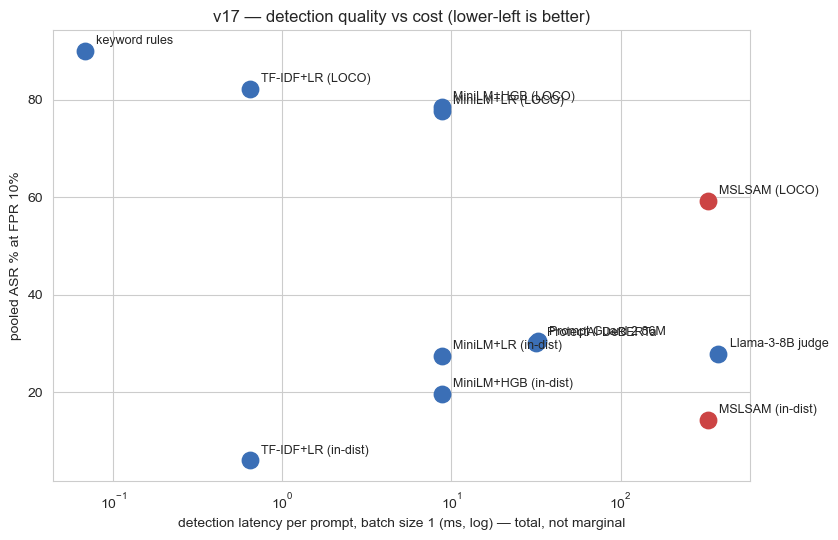

In [14]:
# ================= EXP 3 — cost =============================================
# LATENCY (batch size 1), not batched throughput: a deployment serves one request at a time.
# v17a / v17a2 measured every model this way on this machine. The MSLSAM forward pass is
# measured in MSLSAM's own format by v17a2; the old 2,000 ms figure was v15b's BATCHED
# throughput and is kept only as a fallback.
MSLSAM_FEAT_MS = 3.22
_lat8 = f"{SC_DIR}/_latency_8b.json"
if os.path.exists(_lat8):
    L8 = json.load(open(_lat8)); FWD_MS = L8["mslsam_forward"]
    print(f"MSLSAM forward pass, batch size 1, measured: {FWD_MS:.1f} ms")
else:
    FWD_MS = 2000.0
    print("WARNING: no measured 8B latency (run v17a2). Using v15b's batched throughput,")
    print("         2000 ms -- NOT a latency. Do not cite the cost table until this is fixed.")
ROWS = []
for m in ORDER:
    if m.startswith("mslsam"):
        ROWS.append(dict(method=LBL[m], params=8.03e9, own_pass_ms=FWD_MS,
                         extra_ms=MSLSAM_FEAT_MS,
                         marginal_ms=MSLSAM_FEAT_MS,       # reuses the protected model's pass
                         total_ms=FWD_MS + MSLSAM_FEAT_MS,
                         pooled_asr=E[m]["_pooled_asr"]))
    else:
        c = COST.get(COST_KEY.get(m, m), {})
        ms = c.get("latency_bs1_ms", c.get("ms_per_prompt", np.nan))
        pr = c.get("params", np.nan)
        ROWS.append(dict(method=LBL[m], params=pr, own_pass_ms=ms, extra_ms=0.0,
                         marginal_ms=ms,                   # a separate model: all of it is extra
                         total_ms=ms, pooled_asr=E[m]["_pooled_asr"]))
CT = pd.DataFrame(ROWS)
print(CT.assign(params_M=lambda d: (d.params/1e6).round(0)).drop(columns="params")
        .round(3).to_string(index=False))
print(f"""
  READ THIS CAREFULLY -- the two cost columns answer different questions.

  total_ms     : compute spent on detection alone. A dedicated small classifier wins here;
                 it is a fraction of one 8B forward pass.
  marginal_ms  : compute ADDED when the protected 8B model is already processing the prompt.
                 MSLSAM reuses that pass, so it adds {MSLSAM_FEAT_MS} ms ({MSLSAM_FEAT_MS/FWD_MS*100:.2f}%).
                 Every other method is a SEPARATE model and adds its full cost.

  The Llama-3-8B judge is the sharp case: same model, same one forward pass as MSLSAM, but a
  SECOND pass with its own wrapper prompt -- so ~{FWD_MS:.0f} ms marginal against MSLSAM's {MSLSAM_FEAT_MS}.
  State both columns. Quoting only the marginal one would be an overclaim.""")

fig, ax = plt.subplots(figsize=(8.5, 5.5))
for _, r in CT.iterrows():
    if np.isnan(r.total_ms) or np.isnan(r.pooled_asr): continue
    ax.scatter(max(r.total_ms, 1e-3), r.pooled_asr, s=140,
               c="#c44" if "MSLSAM" in r.method else "#3b6fb6", zorder=3)
    ax.annotate(r.method, (max(r.total_ms, 1e-3), r.pooled_asr),
                textcoords="offset points", xytext=(8, 5), fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("detection latency per prompt, batch size 1 (ms, log) — total, not marginal")
ax.set_ylabel("pooled ASR % at FPR 10%")
ax.set_title("v17 — detection quality vs cost (lower-left is better)")
plt.tight_layout(); plt.savefig(f"outputs/{FIG}_cost_vs_asr.png", dpi=160)
plt.savefig(f"{RES}/{FIG}_cost_vs_asr.png", dpi=160); plt.show()

In [15]:
# ---- persist + verdict -----------------------------------------------------
strip = lambda d: {k: v for k, v in d.items()} if d else None
json.dump(dict(version="v17", run_at=pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"),
               protocol="nested per-context thresholds at FPR 10%, identical for every method",
               methods=ORDER, exp1_by_family={m: strip(E[m]) for m in ORDER},
               exp1b_trained_paired=E1B, exp2_hardneg=E2, exp3_cost=CT.to_dict(orient="records"),
               provenance={k: {kk: v.get(kk) for kk in ("hf_id","commit","accessed","archived_upstream")} for k, v in COST.items()}),
          open(f"{RES}/metrics.json", "w"), indent=2, default=float)
S.to_csv(f"{RES}/all_scores.csv", index=False)
print(f"wrote {RES}/metrics.json + all_scores.csv")

print("\n--- VERDICT ---")
# An ASR is only meaningful at a VALID operating point. Run 1's verdict read the ASR column
# alone and crowned a method whose FPR was 100%. Every method's WORST own-context FPR is now
# checked, and only methods inside budget (+2 pts resampling slack) can be "best".
FPR_OK = FPR_BUDGET*100 + 2.0
worst_fpr = {m: max(E[m][f]["fpr"][0] for f in PAIR if f in E[m]) for m in ORDER}
print("  worst own-context FPR per method (must be ~10% for its ASR to mean anything):")
for m in ORDER:
    print(f"    {LBL[m]:<22}{worst_fpr[m]:6.1f}%" + ("" if worst_fpr[m] <= FPR_OK else "   <- INVALID operating point"))
zs = [m for m in ORDER if m in ZERO_SHOT and worst_fpr[m] <= FPR_OK]
if zs and "mslsam_loco" in E:
    best_zs = min(zs, key=lambda m: E[m]["_pooled_asr"])
    ml, mi = E["mslsam_loco"]["_pooled_asr"], E["mslsam_indist"]["_pooled_asr"]
    print(f"  best zero-shot baseline : {LBL[best_zs]} at {E[best_zs]['_pooled_asr']:.2f}% pooled ASR")
    print(f"  MSLSAM leave-one-out    : {ml:.2f}%   <- the fair comparison")
    print(f"  MSLSAM in-distribution  : {mi:.2f}%   <- upper bound, has seen the family")
    if ml < E[best_zs]["_pooled_asr"]:
        print(f"  -> MSLSAM beats the best zero-shot baseline even without seeing the family.")
    else:
        print(f"  -> MSLSAM does NOT beat {LBL[best_zs]} zero-shot. The contribution is then the")
        print(f"     COST argument ({MSLSAM_FEAT_MS} ms marginal) and the in-distribution ceiling,")
        print(f"     not raw detection. Say so plainly.")
for f in PAIR:
    if "rule_count" in E and f in E["rule_count"] and "mslsam_indist" in E and f in E["mslsam_indist"] \
       and E["rule_count"][f]["fpr"][0] <= FPR_OK:
        r, m_ = E["rule_count"][f]["asr"][0], E["mslsam_indist"][f]["asr"][0]
        if r <= m_: print(f"  WARNING: keyword rules match or beat MSLSAM on {f} "
                          f"({r:.2f}% vs {m_:.2f}%). That is the headline, not a footnote.")
# ---- trained vs trained: does MSLSAM's in-distribution lead survive? ---------
tr_in = [m for m in ORDER if m.endswith("_indist") and not m.startswith("mslsam")
         and worst_fpr.get(m, 99) <= FPR_OK]
if tr_in and "mslsam_indist" in E:
    bt = min(tr_in, key=lambda m: E[m]["_pooled_asr"])
    gap = E[bt]["_pooled_asr"] - E["mslsam_indist"]["_pooled_asr"]
    print(f"\n  best TRAINED text baseline, in-dist: {LBL[bt]} at {E[bt]['_pooled_asr']:.2f}%"
          f"  vs MSLSAM in-dist {E['mslsam_indist']['_pooled_asr']:.2f}%  (MSLSAM ahead by {gap:+.2f} pts)")
    if gap <= 2.0:
        print("  -> PRE-REGISTERED READING: a trained text classifier matches or beats MSLSAM in-dist.")
        print("     MSLSAM's in-distribution lead is the TRAINING DATA, not the hidden states.")
    else:
        print("  -> MSLSAM leads the best trained baseline by more than 2 pts pooled. A CANDIDATE")
        print("     representational advantage -- claim it only for families where Exp 1b's McNemar")
        print("     says 'MSLSAM' at p < 0.05.")
        wins = [f for f, v in E1B.get("indist", {}).get("families", {}).items()
                if v["significantly_better"] == "MSLSAM"]
        print(f"     significant MSLSAM wins: {wins or 'none'}")
print("\nUpdate versions/16_mslsam-v17/README.md, EXPERIMENTS.md, AGENTS.md (R2/R3/R5).")

wrote results/v17/metrics.json + all_scores.csv

--- VERDICT ---
  worst own-context FPR per method (must be ~10% for its ASR to mean anything):
    keyword rules            1.9%
    ProtectAI DeBERTa       10.5%
    Prompt Guard 2 86M      10.6%
    Llama-3-8B judge        10.6%
    TF-IDF+LR (LOCO)        10.6%
    MiniLM+LR (LOCO)        10.6%
    MiniLM+HGB (LOCO)       10.5%
    MSLSAM (LOCO)           10.5%
    TF-IDF+LR (in-dist)     10.5%
    MiniLM+LR (in-dist)     10.6%
    MiniLM+HGB (in-dist)    10.6%
    MSLSAM (in-dist)        10.7%
  best zero-shot baseline : Llama-3-8B judge at 27.83% pooled ASR
  MSLSAM leave-one-out    : 59.18%   <- the fair comparison
  MSLSAM in-distribution  : 14.42%   <- upper bound, has seen the family
  -> MSLSAM does NOT beat Llama-3-8B judge zero-shot. The contribution is then the
     COST argument (3.22 ms marginal) and the in-distribution ceiling,
     not raw detection. Say so plainly.

  best TRAINED text baseline, in-dist: TF-IDF+LR (in-